In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
import glob
import sunpy.visualization.colormaps as cm

#### SpeedNet-BM Phase Attribution Plots

In [3]:
evaluation_path = "../DATASET/Results/SpeedNet_BM/Phase/Evaluation_path"

In [4]:
ascending_phase_df = pd.read_csv(os.path.join(evaluation_path, "Ascending_results/prediction_ascending_fold1_delay4.csv"))
maximum_phase_df = pd.read_csv(os.path.join(evaluation_path, "Maximum_results/prediction_maximum_fold2_delay3.csv"))
descending_phase_df = pd.read_csv(os.path.join(evaluation_path, "Declining_results/prediction_declining_fold4_delay4.csv"))
minimum_phase_df = pd.read_csv(os.path.join(evaluation_path, "Minimum_results/prediction_minimum_fold2_delay5.csv"))

In [5]:
print(ascending_phase_df.isna().sum())
print(maximum_phase_df.isna().sum())
print(descending_phase_df.isna().sum())
print(minimum_phase_df.isna().sum())

date                0
test_original     127
test_predicted    127
std_original      127
dtype: int64
date                0
test_original     310
test_predicted    310
std_original      310
dtype: int64
date                0
test_original     236
test_predicted    236
std_original      236
dtype: int64
date               0
test_original     67
test_predicted    67
std_original      67
dtype: int64


In [6]:
ascending_phase_df = ascending_phase_df.dropna()
maximum_phase_df = maximum_phase_df.dropna()
descending_phase_df = descending_phase_df.dropna()
minimum_phase_df = minimum_phase_df.dropna()

In [7]:
print(ascending_phase_df.isna().sum())
print(maximum_phase_df.isna().sum())
print(descending_phase_df.isna().sum())
print(minimum_phase_df.isna().sum())

date              0
test_original     0
test_predicted    0
std_original      0
dtype: int64
date              0
test_original     0
test_predicted    0
std_original      0
dtype: int64
date              0
test_original     0
test_predicted    0
std_original      0
dtype: int64
date              0
test_original     0
test_predicted    0
std_original      0
dtype: int64


In [8]:
### Find the index of this HSS events

import pandas as pd

def format_to_ymd(date_str: str) -> str:
    dt = pd.to_datetime(date_str)
    return dt.strftime("%Y-%m-%d")


In [9]:
Ascending_HSS_date = format_to_ymd("2011-03-04")
Maximum_HSS_date = format_to_ymd("2012-04-13")
Descending_HSS_date = format_to_ymd("2018-10-09")
Minimum_HSS_date = format_to_ymd("2019-10-26")

# Convert df["date"] to datetime (no time part)
ascending_phase_df["date"] = pd.to_datetime(ascending_phase_df["date"]).dt.normalize()
maximum_phase_df["date"]   = pd.to_datetime(maximum_phase_df["date"]).dt.normalize()
descending_phase_df["date"] = pd.to_datetime(descending_phase_df["date"]).dt.normalize()
minimum_phase_df["date"]   = pd.to_datetime(minimum_phase_df["date"]).dt.normalize()

# Also normalize your target dates
Ascending_HSS_date  = pd.to_datetime(Ascending_HSS_date).normalize()
Maximum_HSS_date    = pd.to_datetime(Maximum_HSS_date).normalize()
Descending_HSS_date = pd.to_datetime(Descending_HSS_date).normalize()
Minimum_HSS_date    = pd.to_datetime(Minimum_HSS_date).normalize()


In [10]:
ascending_peak_idx = ascending_phase_df.index[ascending_phase_df["date"] == Ascending_HSS_date]
maximum_peak_idx = maximum_phase_df.index[maximum_phase_df["date"] == Maximum_HSS_date]
descending_peak_idx = descending_phase_df.index[descending_phase_df["date"] == Descending_HSS_date]
minimum_peak_idx = minimum_phase_df.index[minimum_phase_df["date"] == Minimum_HSS_date]

In [11]:
ascending_pos = ascending_phase_df.index.get_loc(ascending_peak_idx.item())


print(ascending_phase_df["date"].iloc[ascending_pos])

maximum_pos = maximum_phase_df.index.get_loc(maximum_peak_idx.item())
print(maximum_phase_df["date"].iloc[maximum_pos])

descending_pos = descending_phase_df.index.get_loc(descending_peak_idx.item())
print(descending_phase_df["date"].iloc[descending_pos])

minimum_pos = minimum_phase_df.index.get_loc(minimum_peak_idx.item())
print(minimum_phase_df["date"].iloc[minimum_pos])


print("Ascending HSS Peak Index:", ascending_pos)
print("Maximum HSS Peak Index:", maximum_pos)
print("Descending HSS Peak Index:", descending_pos)
print("Minimum HSS Peak Index:", minimum_pos)


2011-03-04 00:00:00
2012-04-13 00:00:00
2018-10-09 00:00:00
2019-10-26 00:00:00
Ascending HSS Peak Index: 252
Maximum HSS Peak Index: 67
Descending HSS Peak Index: 1142
Minimum HSS Peak Index: 275


In [13]:
Ascending_img_path_1 = os.path.join(evaluation_path,"Ascending_results/Attribution/Input_Maps/")
Ascending_img_path_2 = os.path.join(evaluation_path,"Ascending_results/Attribution/Gradcam/")
Ascending_img_path_3 = os.path.join(evaluation_path,"Ascending_results/Attribution/IG/")
Ascending_img_path_4 = os.path.join(evaluation_path,"Ascending_results/Attribution/Input_Maps_Standardized/")

Maximum_img_path_1 = os.path.join(evaluation_path,"Maximum_results/Attribution/Input_Maps/")
Maximum_img_path_2 = os.path.join(evaluation_path,"Maximum_results/Attribution/Gradcam/")
Maximum_img_path_3 = os.path.join(evaluation_path,"Maximum_results/Attribution/IG/")
Maximum_img_path_4 = os.path.join(evaluation_path,"Maximum_results/Attribution/Input_Maps_Standardized/")

Declining_img_path_1 = os.path.join(evaluation_path,"Declining_results/Attribution/Input_Maps/")
Declining_img_path_2 = os.path.join(evaluation_path,"Declining_results/Attribution/Gradcam/")
Declining_img_path_3 = os.path.join(evaluation_path,"Declining_results/Attribution/IG/")
Declining_img_path_4 = os.path.join(evaluation_path,"Declining_results/Attribution/Input_Maps_Standardized/")

Minimum_img_path_1 = os.path.join(evaluation_path,"Minimum_results/Attribution/Input_Maps/")
Minimum_img_path_2 = os.path.join(evaluation_path,"Minimum_results/Attribution/Gradcam/")
Minimum_img_path_3 = os.path.join(evaluation_path,"Minimum_results/Attribution/IG/")
Minimum_img_path_4 = os.path.join(evaluation_path,"Minimum_results/Attribution/Input_Maps_Standardized/")


# Sorted npy files
Ascending_SpeedNet_BM_map = sorted(glob.glob(os.path.join(Ascending_img_path_1, "*.npy")))
Ascending_SpeedNet_Gradcam_map  = sorted(glob.glob(os.path.join(Ascending_img_path_2, "*.npy")))
Ascending_SpeedNet_IG_map  = sorted(glob.glob(os.path.join(Ascending_img_path_3, "*.npy")))
Ascending_SpeedNet_193_map = sorted(glob.glob(os.path.join(Ascending_img_path_4, "*.npy")))

Maximum_SpeedNet_BM_map = sorted(glob.glob(os.path.join(Maximum_img_path_1, "*.npy")))
Maximum_SpeedNet_Gradcam_map  = sorted(glob.glob(os.path.join(Maximum_img_path_2, "*.npy")))
Maximum_SpeedNet_IG_map  = sorted(glob.glob(os.path.join(Maximum_img_path_3, "*.npy")))
Maximum_SpeedNet_193_map = sorted(glob.glob(os.path.join(Maximum_img_path_4, "*.npy")))

Declining_SpeedNet_BM_map = sorted(glob.glob(os.path.join(Declining_img_path_1, "*.npy")))
Declining_SpeedNet_Gradcam_map  = sorted(glob.glob(os.path.join(Declining_img_path_2, "*.npy")))
Declining_SpeedNet_IG_map  = sorted(glob.glob(os.path.join(Declining_img_path_3, "*.npy")))
Declining_SpeedNet_193_map = sorted(glob.glob(os.path.join(Declining_img_path_4, "*.npy")))

Minimum_SpeedNet_BM_map = sorted(glob.glob(os.path.join(Minimum_img_path_1, "*.npy")))
Minimum_SpeedNet_Gradcam_map  = sorted(glob.glob(os.path.join(Minimum_img_path_2, "*.npy")))
Minimum_SpeedNet_IG_map  = sorted(glob.glob(os.path.join(Minimum_img_path_3, "*.npy")))
Minimum_SpeedNet_193_map = sorted(glob.glob(os.path.join(Minimum_img_path_4, "*.npy")))


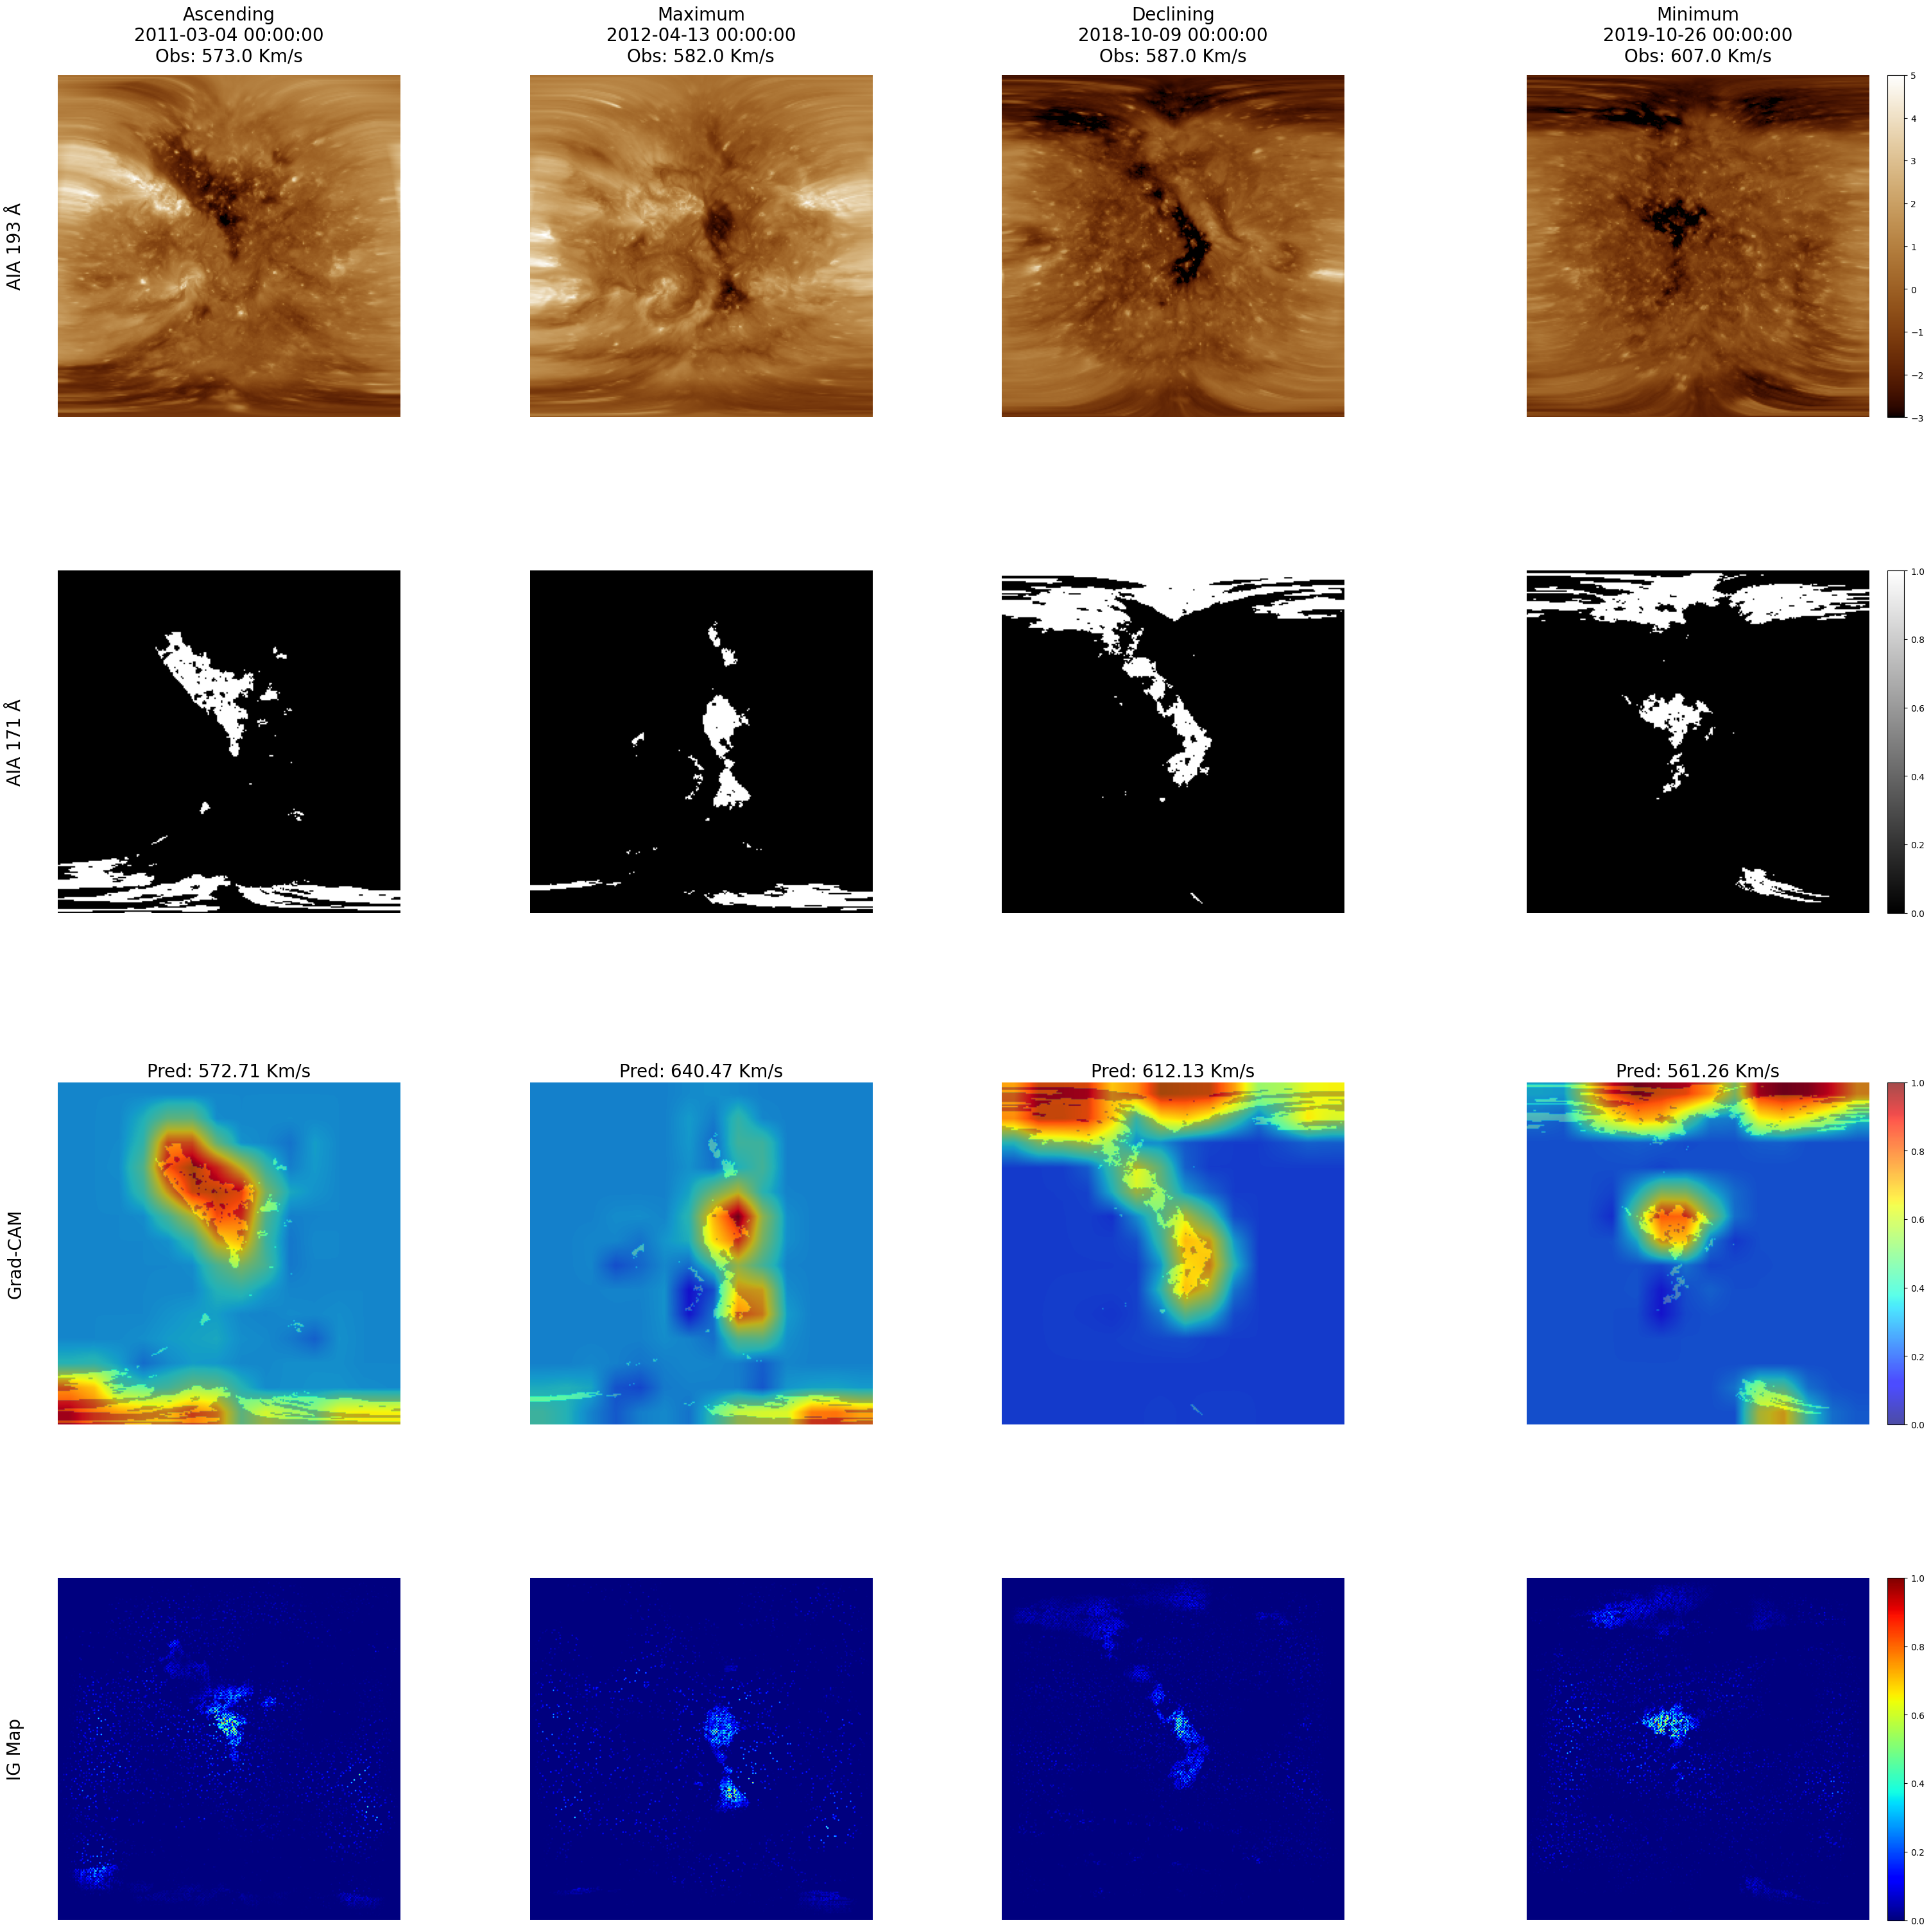

In [15]:

# ----------------------------------------------------
# Organize paths + metadata per phase
# ----------------------------------------------------
phase_maps = {
    "Ascending": {
        "193": Ascending_SpeedNet_193_map,
        "BM": Ascending_SpeedNet_BM_map,
        "Gradcam": Ascending_SpeedNet_Gradcam_map,
        "IG": Ascending_SpeedNet_IG_map,
        "index": ascending_pos,
        "df": ascending_phase_df
    },
    "Maximum": {
        "193": Maximum_SpeedNet_193_map,
        "BM": Maximum_SpeedNet_BM_map,
        "Gradcam": Maximum_SpeedNet_Gradcam_map,
        "IG": Maximum_SpeedNet_IG_map,
        "index": maximum_pos,
        "df": maximum_phase_df
    },
    "Declining": {
        "193": Declining_SpeedNet_193_map,
        "BM": Declining_SpeedNet_BM_map,
        "Gradcam": Declining_SpeedNet_Gradcam_map,
        "IG": Declining_SpeedNet_IG_map,
        "index": descending_pos,
        "df": descending_phase_df
    },
    "Minimum": {
        "193": Minimum_SpeedNet_193_map,
        "BM": Minimum_SpeedNet_BM_map,
        "Gradcam": Minimum_SpeedNet_Gradcam_map,
        "IG": Minimum_SpeedNet_IG_map,
        "index": minimum_pos,
        "df": minimum_phase_df
    }
}

# ----------------------------------------------------
# Create 5×4 figure
# ----------------------------------------------------
fig, axs = plt.subplots(
    4, 4,
    figsize=(30, 30),
    gridspec_kw={'wspace': 0.05, 'hspace': 0.3,
                 'left': 0.01, 'right': 0.95,
                 'top': 0.97, 'bottom': 0.03},
    constrained_layout=True
)

row_labels = ["AIA 193 Å", "AIA 171 Å", "AIA 304 Å", "Grad-CAM", "IG Map"]
col_labels = list(phase_maps.keys())

for col, phase in enumerate(col_labels):

    # Pick correct data
    phase_info = phase_maps[phase]
    # Make sure idx is a plain integer
    idx = phase_info["index"]

    df = phase_info["df"]
    # print(idx)
    # Load arrays
    arr_euv = np.load(phase_info["193"][idx])      # (H, W, 3)
    # print(arr_np.shape)
    # arr_euv = arr_np[idx,:,:,:]
    arr_bm = np.load(phase_info["BM"][idx])      # (H, W, 3)
    arr_grad = np.load(phase_info["Gradcam"][idx]) # (H, W) or (H, W, 1)
    arr_ig = np.load(phase_info["IG"][idx])        # (H, W) or (H, W, 1)

    # Extract meta info from phase-specific df
    SW_date = df["date"].iloc[idx]
    # print(SW_date)
    obs_val = df["test_original"].iloc[idx]
    pred_val = df["test_predicted"].iloc[idx]

    # ------------------------
    # Row 0: AIA 193
    im193 = axs[0, col].imshow(arr_euv, cmap="sdoaia193", vmin=-3, vmax=5)
    axs[0, col].axis("off")
    axs[0, col].set_title(
        f"{phase}\n{SW_date}\nObs: {obs_val:.1f} Km/s",
        fontsize=20, pad=15
    )
    if col == 0:
        axs[0, col].text(-0.15, 0.5, row_labels[0], fontsize=20, rotation=90,
                         transform=axs[0, col].transAxes, va="center")
    if col == len(col_labels)-1:
        fig.colorbar(im193, ax=axs[0, col], fraction=0.05, pad=0.04)

    # ------------------------
    # Row 1: Binary map
    binary_im = axs[1, col].imshow(arr_bm, cmap="gray", vmin=0, vmax=1)
    axs[1, col].axis("off")
    if col == 0:
        axs[1, col].text(-0.15, 0.5, row_labels[1], fontsize=20, rotation=90,
                         transform=axs[1, col].transAxes, va="center")
    if col == len(col_labels)-1:
        fig.colorbar(binary_im, ax=axs[1, col], fraction=0.05, pad=0.04)

    
    # # ------------------------
    # Row 2: Grad-CAM overlay
    # arr_euv_map_sum = np.sum(arr_euv, axis=2)
    # arr_euv_map_sum_clip = np.clip(arr_euv_map_sum, 0, np.max(arr_euv_map_sum)) / np.max(arr_euv_map_sum)
    # axs[2, col].imshow(arr_euv_map_sum_clip)
    axs[2, col].imshow(arr_bm)
    grad = arr_grad[:, :, 0] if arr_grad.ndim == 3 else arr_grad
    grad_norm = np.clip(grad, 0, np.max(grad)) / np.max(grad)
    im_grad = axs[2, col].imshow(grad_norm, cmap="jet", alpha=0.7, vmin=0, vmax=1)
    axs[2, col].axis("off")
    axs[2, col].set_title(f"Pred: {pred_val:.2f} Km/s", fontsize=20)
    if col == 0:
        axs[2, col].text(-0.15, 0.5, row_labels[3], fontsize=20, rotation=90,
                         transform=axs[2, col].transAxes, va="center")
    if col == len(col_labels)-1:
        fig.colorbar(im_grad, ax=axs[2, col], fraction=0.05, pad=0.04)

    # ------------------------
    # Row 4: IG
    ig_map = arr_ig[:, :, 0] 
    ig_norm = np.clip(ig_map, 0, np.max(ig_map)) / np.max(ig_map)
    im_ig = axs[3, col].imshow(ig_norm, cmap="jet", vmin=0, vmax=1)
    axs[3, col].axis("off")
    if col == 0:
        axs[3, col].text(-0.15, 0.5, row_labels[4], fontsize=20, rotation=90,
                         transform=axs[3, col].transAxes, va="center")
    if col == len(col_labels)-1:
        fig.colorbar(im_ig, ax=axs[3, col], fraction=0.05, pad=0.04)

# ----------------------------------------------------
# Save or show
# ----------------------------------------------------
plt.savefig("../DATASET/Results/SpeedNet_BM/Phase/SpeedNet_BM_phase_plot/SpeedNet_Phases_Comparison.png", dpi=500, bbox_inches="tight")
plt.savefig("../DATASET/Results/SpeedNet_BM/Phase/SpeedNet_BM_phase_plot/SpeedNet_Phases_Comparison.pdf", dpi=500, bbox_inches="tight")
plt.show()
